# Task 2: Background removal for a meeting camera

**Goal.** Train a **binary segmentation** model (a **U-Net**) that predicts, for every pixel, *person or background*.
Then use it on your laptop camera to put a new background behind you, like a video call.

**Data.** [Supervisely filtered person dataset](https://www.kaggle.com/datasets/tapakah68/supervisely-filtered-segmentation-person-dataset): 2,667 photos with a person mask each.
Check the dataset's licence on Kaggle before using it beyond this class.

## 0. Setup

In [1]:
!pip -q install kagglehub

In [13]:
import os, glob, random, time
import numpy as np, cv2
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
from torchvision.models.segmentation import deeplabv3_resnet50, DeepLabV3_ResNet50_Weights
from PIL import Image

SEED = 42

## 1. Download and look at the data
The first cell downloads the dataset. It is a few hundred MB, so it takes a minute.

In [3]:
# [colab-only] download the dataset from Kaggle
import kagglehub

DATASET = "tapakah68/supervisely-filtered-segmentation-person-dataset"
try:
    DATA_ROOT = kagglehub.dataset_download(DATASET)
except Exception as e:
    # Fallback: use your own Kaggle API key (Kaggle > Settings > API > Create New Token)
    print("kagglehub could not download without login:", type(e).__name__)
    from google.colab import files
    print("Upload your kaggle.json")
    files.upload()
    os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
    !cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
    !kaggle datasets download -d {DATASET} -p /content/data --unzip -q
    DATA_ROOT = "/content/data"
print("dataset folder:", DATA_ROOT)

Using Colab cache for faster access to the 'supervisely-filtered-segmentation-person-dataset' dataset.
dataset folder: /kaggle/input/supervisely-filtered-segmentation-person-dataset


In [4]:
# Find every image and its mask, and pair them by file name.
IMG_EXT = (".png", ".jpg", ".jpeg", ".bmp")
IMG_DIR = None    # set both by hand only if the automatic search below fails
MASK_DIR = None

def stem(path):
    s = os.path.splitext(os.path.basename(path))[0].lower()
    for tag in ("_mask", "-mask", "mask_", "mask-", "_seg", "_label"):
        s = s.replace(tag, "")
    return s

def find_pairs(root):
    files = [f for f in glob.glob(os.path.join(root, "**", "*"), recursive=True)
             if f.lower().endswith(IMG_EXT)]
    rel = lambda f: os.path.relpath(f, root).lower()
    is_mask    = lambda f: "mask" in rel(f)
    is_collage = lambda f: "collage" in rel(f)     # photo + mask drawn together: NOT the original photo
    imgs  = {stem(f): f for f in files if not is_mask(f) and not is_collage(f)}
    masks = {stem(f): f for f in files if is_mask(f)}
    keys = sorted(set(imgs) & set(masks))
    return [(imgs[k], masks[k]) for k in keys]

if IMG_DIR and MASK_DIR:
    imgs  = {stem(f): f for f in glob.glob(os.path.join(IMG_DIR, "*"))}
    masks = {stem(f): f for f in glob.glob(os.path.join(MASK_DIR, "*"))}
    pairs = [(imgs[k], masks[k]) for k in sorted(set(imgs) & set(masks))]
else:
    pairs = find_pairs(DATA_ROOT)

print("image/mask pairs found:", len(pairs))
from collections import Counter
print("folders used:", dict(Counter(os.path.basename(os.path.dirname(p)) for pr in pairs for p in pr)))
if not pairs:
    for dp, dn, fn in os.walk(DATA_ROOT):
        print(dp, "->", len(fn), "files", fn[:3])
    raise RuntimeError("No pairs found. Look at the folder listing above and set IMG_DIR and MASK_DIR.")
print(pairs[0])

image/mask pairs found: 2663
folders used: {'images': 2663, 'masks': 2663}
('/kaggle/input/supervisely-filtered-segmentation-person-dataset/supervisely_person_clean_2667_img/supervisely_person_clean_2667_img/images/ds10_pexels-photo-687782.png', '/kaggle/input/supervisely-filtered-segmentation-person-dataset/supervisely_person_clean_2667_img/supervisely_person_clean_2667_img/masks/ds10_pexels-photo-687782.png')


In [5]:
def read_mask(path):
    """Mask file -> 2-D array. If the file has colour channels, take the strongest one."""
    return cv2.imread(path, cv2.IMREAD_COLOR).max(axis=2)

# How are the masks encoded? The person may be 255, 1 or something else. Never guess: measure.
sample = random.sample(pairs, min(100, len(pairs)))
vals = np.unique(np.concatenate([np.unique(read_mask(mp)) for _, mp in sample]))
MASK_MAX = int(vals.max())
MASK_THRESHOLD = MASK_MAX / 2        # above this = person, whatever the file uses (255, 1, ...)
frac = np.mean([(read_mask(mp) > MASK_THRESHOLD).mean() for _, mp in sample])
print("distinct mask values:", vals[:10], "| max:", MASK_MAX, "| threshold:", MASK_THRESHOLD)
print(f"average person share of an image: {frac:.1%}")
assert MASK_MAX > 0 and 0.02 < frac < 0.9, "The masks look empty or full. Check the pairing and the values printed above."

# An image and its mask must have the same size. Many mismatches mean the wrong folder was paired.
mismatch = sum(cv2.imread(ip).shape[:2] != read_mask(mp).shape[:2] for ip, mp in sample)
print("image/mask size mismatches in the sample:", mismatch, "of", len(sample))
assert mismatch < 0.5 * len(sample), "Most images have a different size than their mask: the wrong image folder is probably paired. Check 'folders used' above."

distinct mask values: [  0 255] | max: 255 | threshold: 127.5
average person share of an image: 31.7%
image/mask size mismatches in the sample: 0 of 100


**Always open a mask and print its values before training.** Masks are stored as PNG, but the foreground may be `255`, `1`, or anything else.
The cell above measured the mask values and set `MASK_THRESHOLD` for you. Look at the `mask values` printed above each mask too.

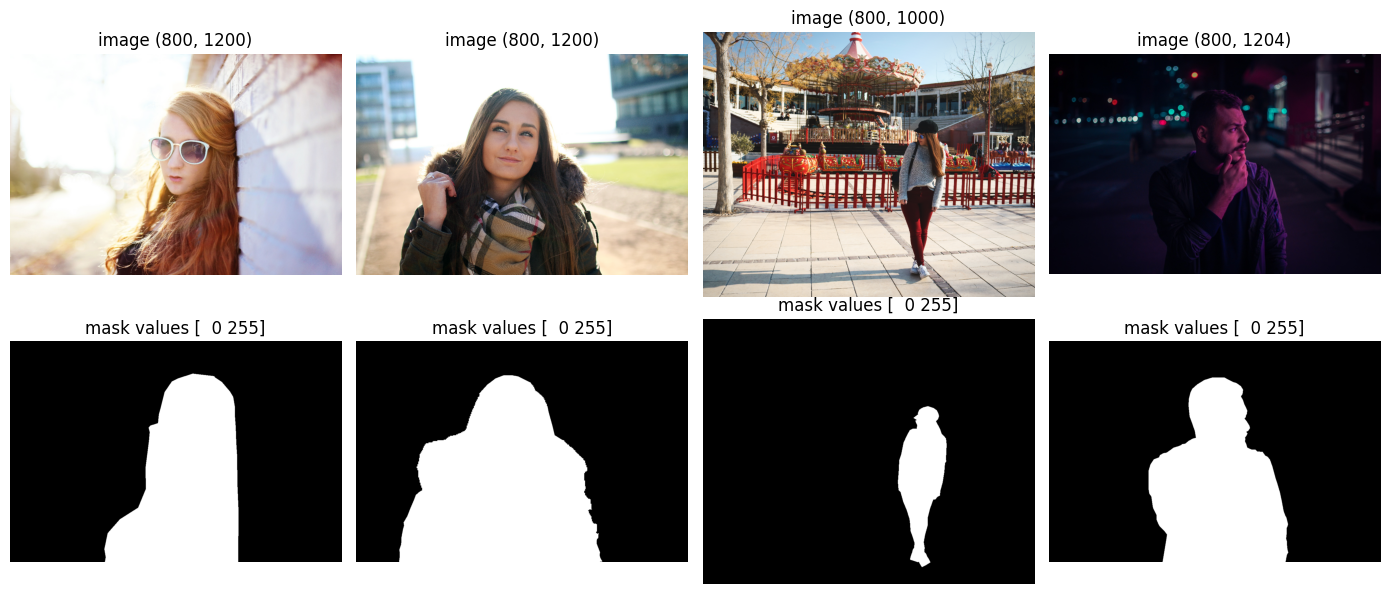

In [6]:
# Look at the data. A mask is data: print its values before you trust it.
fig, ax = plt.subplots(2, 4, figsize=(14, 6))
for k, i in enumerate(random.sample(range(len(pairs)), 4)):
    ip, mp = pairs[i]
    img = cv2.cvtColor(cv2.imread(ip), cv2.COLOR_BGR2RGB)
    msk = read_mask(mp)
    ax[0, k].imshow(img); ax[0, k].set_title(f"image {img.shape[:2]}"); ax[0, k].axis("off")
    ax[1, k].imshow(msk, cmap="gray"); ax[1, k].set_title(f"mask values {np.unique(msk)[:4]}"); ax[1, k].axis("off")
plt.tight_layout(); plt.show()

In [7]:
# Train / validation split (the validation images are never used for training)
random.Random(SEED).shuffle(pairs)
n_val = int(0.15 * len(pairs))
val_pairs, train_pairs = pairs[:n_val], pairs[n_val:]
print("train:", len(train_pairs), " val:", len(val_pairs))

train: 2264  val: 399


In [14]:
# 1. Define the Dataset
class PersonDataset(Dataset):
    def __init__(self, pairs, img_size=(256, 256)):
        self.pairs = pairs
        self.img_size = img_size
        self.transform = transforms.Compose([
            transforms.Resize(img_size),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
        ])
        self.mask_transform = transforms.Compose([
            transforms.Resize(img_size, interpolation=Image.NEAREST),
            transforms.ToTensor()
        ])

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        img_path, mask_path = self.pairs[idx]
        image = Image.open(img_path).convert("RGB")
        mask = Image.open(mask_path).convert("L")

        image_tensor = self.transform(image)
        mask_tensor = self.mask_transform(mask)
        mask_tensor = (mask_tensor > (MASK_THRESHOLD / 255.0)).float()
        return image_tensor, mask_tensor

In [15]:
# 2. Setup Data Loaders
train_dataset = PersonDataset(train_pairs)
val_dataset = PersonDataset(val_pairs)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False, num_workers=2, pin_memory=True)



In [16]:
# 3. Load Pre-trained Model and Fine-tune Classifier Head
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device)

# Load pre-trained DeepLabV3 model
weights = DeepLabV3_ResNet50_Weights.DEFAULT
model = deeplabv3_resnet50(weights=weights)

# Modify the classifier head for binary output (1 channel)
in_channels = model.classifier[4].in_channels
model.classifier[4] = nn.Conv2d(in_channels, 1, kernel_size=1)

# Modify the auxiliary classifier if it exists
if model.aux_classifier is not None:
    in_channels_aux = model.aux_classifier[4].in_channels
    model.aux_classifier[4] = nn.Conv2d(in_channels_aux, 1, kernel_size=1)

model = model.to(device)

# 4. Define Loss & Optimizer
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

Using device: cuda
Downloading: "https://download.pytorch.org/models/deeplabv3_resnet50_coco-cd0a2569.pth" to /root/.cache/torch/hub/checkpoints/deeplabv3_resnet50_coco-cd0a2569.pth


100%|██████████| 161M/161M [00:00<00:00, 180MB/s]


In [17]:
# 5. Fine-tuning Loop (1 Epoch Demo)
print("Starting fine-tuning...")
model.train()
for epoch in range(1):
    running_loss = 0.0
    for batch_idx, (imgs, masks) in enumerate(train_loader):
        imgs, masks = imgs.to(device), masks.to(device)

        optimizer.zero_grad()
        outputs = model(imgs)['out']
        loss = criterion(outputs, masks)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        if (batch_idx + 1) % 20 == 0:
            print(f"Epoch [{epoch+1}/1], Batch [{batch_idx+1}/{len(train_loader)}], Loss: {running_loss / (batch_idx + 1):.4f}")

print("Pre-trained segmentation model fine-tuned successfully!")

Starting fine-tuning...
Epoch [1/1], Batch [20/142], Loss: 0.4712
Epoch [1/1], Batch [40/142], Loss: 0.3428
Epoch [1/1], Batch [60/142], Loss: 0.2929
Epoch [1/1], Batch [80/142], Loss: 0.2605
Epoch [1/1], Batch [100/142], Loss: 0.2388
Epoch [1/1], Batch [120/142], Loss: 0.2220
Epoch [1/1], Batch [140/142], Loss: 0.2102
Pre-trained segmentation model fine-tuned successfully!


## Meeting-camera test
Take a photo with your laptop camera, choose a new background, and let your model remove the old one.
The edge is blended with **alpha** (Session 2): a hard 0/1 mask looks jagged, a slightly blurred one looks natural.

Allow camera access when the browser asks. Run the cells below in order.

<IPython.core.display.Javascript object>

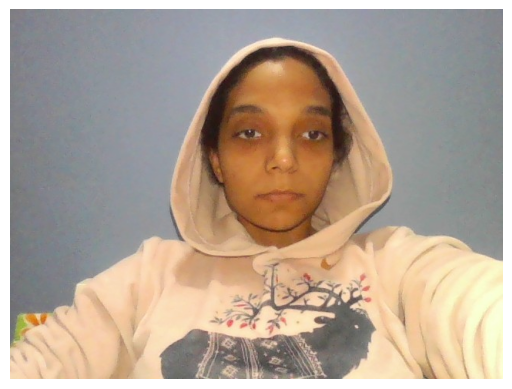

In [18]:
# [colab-only] take a photo with your laptop camera (the browser will ask for permission)
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode

def take_photo(filename="photo.jpg", quality=0.9):
    js = Javascript('''
      async function takePhoto(quality) {
        const div = document.createElement('div');
        const btn = document.createElement('button');
        btn.textContent = 'Capture'; div.appendChild(btn);
        const video = document.createElement('video');
        video.style.display = 'block';
        const stream = await navigator.mediaDevices.getUserMedia({video: true});
        document.body.appendChild(div); div.appendChild(video);
        video.srcObject = stream; await video.play();
        google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);
        await new Promise((resolve) => btn.onclick = resolve);
        const canvas = document.createElement('canvas');
        canvas.width = video.videoWidth; canvas.height = video.videoHeight;
        canvas.getContext('2d').drawImage(video, 0, 0);
        stream.getVideoTracks()[0].stop(); div.remove();
        return canvas.toDataURL('image/jpeg', quality);
      }
    ''')
    display(js)
    data = eval_js("takePhoto({})".format(quality))
    with open(filename, "wb") as f:
        f.write(b64decode(data.split(",")[1]))
    return filename

frame_path = take_photo()
frame = cv2.cvtColor(cv2.imread(frame_path), cv2.COLOR_BGR2RGB)
plt.imshow(frame); plt.axis("off"); plt.show()

In [19]:
# [colab-only] choose the new background: "upload" your own picture, "blur" the real room, or a flat "color"
BACKGROUND = "upload"

if BACKGROUND == "upload":
    from google.colab import files
    up = files.upload()                              # pick any picture
    new_bg = cv2.cvtColor(cv2.imread(next(iter(up))), cv2.COLOR_BGR2RGB)
elif BACKGROUND == "blur":
    new_bg = cv2.GaussianBlur(frame, (0, 0), 25)
else:
    new_bg = np.full_like(frame, (30, 140, 90))      # a green screen

Saving 6a354b6974ba9d9b473c81c9_20221109_detailed-preview_cam-01-RENDY-OFFICE-1920x1080[1].webp to 6a354b6974ba9d9b473c81c9_20221109_detailed-preview_cam-01-RENDY-OFFICE-1920x1080[1].webp


In [24]:
# Define the real replace_background function using our fine-tuned model
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
import torchvision.transforms as transforms
from PIL import Image

def replace_background(frame, new_bg):
    model.eval()
    h, w = frame.shape[:2]
    bg_resized = cv2.resize(new_bg, (w, h))

    # Preprocess the frame for the model
    preprocess = transforms.Compose([
        transforms.Resize((256, 256)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])

    pil_img = Image.fromarray(frame)
    img_tensor = preprocess(pil_img).unsqueeze(0).to(device)

    # Generate prediction mask
    with torch.no_grad():
        output = model(img_tensor)['out']
        pred_mask = torch.sigmoid(output).squeeze(0).squeeze(0).cpu().numpy()

    # Resize predicted mask back to original frame size
    global alpha
    alpha = cv2.resize(pred_mask, (w, h))

    # Blur the alpha mask to smooth the boundaries
    alpha = cv2.GaussianBlur(alpha, (15, 15), 0)

    # Blend the original frame and new background
    alpha_3d = np.expand_dims(alpha, axis=2)
    blend = (frame * alpha_3d + bg_resized * (1.0 - alpha_3d)).astype(np.uint8)
    return blend

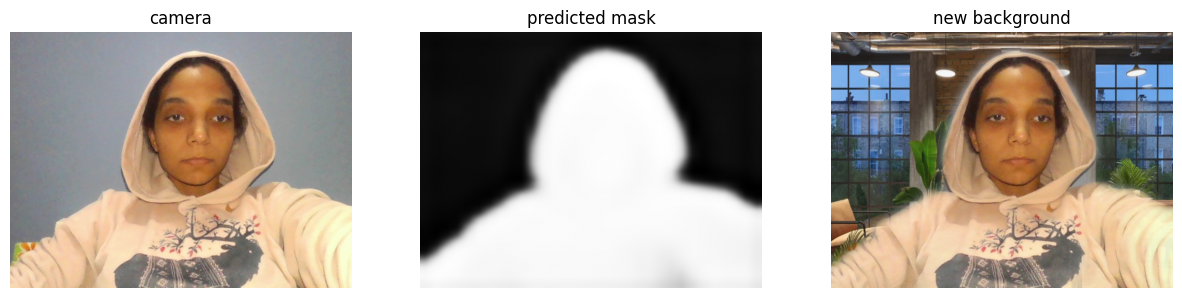

True

In [25]:
# Remove the background and show the result
result = replace_background(frame, new_bg)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(frame);  ax[0].set_title("camera")
ax[1].imshow(alpha, cmap="gray"); ax[1].set_title("predicted mask")
ax[2].imshow(result); ax[2].set_title("new background")
for a in ax: a.axis("off")
plt.show()
cv2.imwrite("result.jpg", cv2.cvtColor(result, cv2.COLOR_RGB2BGR))

In [26]:
# Save the model for future deployment using TorchScript
# This serializes both the architecture and weights so it can be used without this notebook's code

import torch

# Put model in evaluation mode
model.eval()

# Trace or script the model to compile it
try:
    # Using torch.jit.script allows exporting the module structure cleanly
    scripted_model = torch.jit.script(model)
    scripted_model.save("deeplabv3_background_segmentation.pt")
    print("Model successfully compiled and saved to 'deeplabv3_background_segmentation.pt' via TorchScript!")
except Exception as e:
    print(f"TorchScript compilation failed: {e}. Falling back to standard weight saving...")
    # Fallback to standard state_dict if scripting fails
    torch.save(model.state_dict(), "deeplabv3_weights.pth")
    print("Model weights saved to 'deeplabv3_weights.pth'")

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/jit/_recursive.py:442: UserWarning: 'aux_classifier' was found in ScriptModule constants,  but it is a non-constant submodule. Consider removing it.
  concrete_type_builder = infer_concrete_type_builder(nn_module)


Model successfully compiled and saved to 'deeplabv3_background_segmentation.pt' via TorchScript!


In [27]:
# Download the saved TorchScript model file to your local computer
from google.colab import files
import os

model_path = "deeplabv3_background_segmentation.pt"
if os.path.exists(model_path):
    files.download(model_path)
else:
    print(f"{model_path} not found. Did you run the previous cell?")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Load the saved TorchScript model
import torch

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model_path = "deeplabv3_background_segmentation.pt"

try:
    # Load the standalone model
    loaded_model = torch.jit.load(model_path, map_location=device)
    loaded_model.eval()
    print(f"Successfully loaded standalone model from '{model_path}'!")
    print("You can now use 'loaded_model' directly to run inferences without needing any of the training code definitions.")
except Exception as e:
    print(f"Error loading the model: {e}")